In [32]:
import re
from stemming.porter2 import stem
from collections import Counter
from math import log2
from wordcloud import WordCloud
from matplotlib import pyplot as plt
import random

In [2]:
# Prepare the book content
with open("book.txt", "r") as file:
    content = file.read().lower()

punctuation = '.,?!:;\'"’‘“”*()[]_-'
content = re.sub(f"[{re.escape(punctuation)}]", " ", content)

In [3]:
# Exercise 5
def prepare_word_list(words: list) -> Counter:
    with open("stop-words.txt", "r") as file:
        stop_words = file.read().split()
    words = [word for word in words if word not in stop_words]

    words = [stem(word) for word in words]

    pairs = Counter(words) # average-case complexity O(n)
    pairs = sorted(pairs.items(), key=lambda x: x[1], reverse=True)
    pairs = pairs[10:]

    return pairs

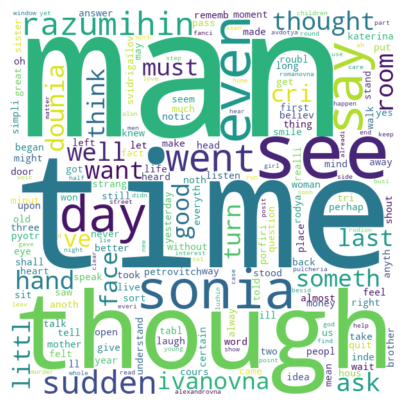

In [15]:
# Exercise 5
pairs = prepare_word_list(content.split())
pairs = {word : weight for word, weight in pairs}

wordcloud = WordCloud(width=600, height=600, background_color='white').generate_from_frequencies(pairs)
plt.figure(figsize=(5, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

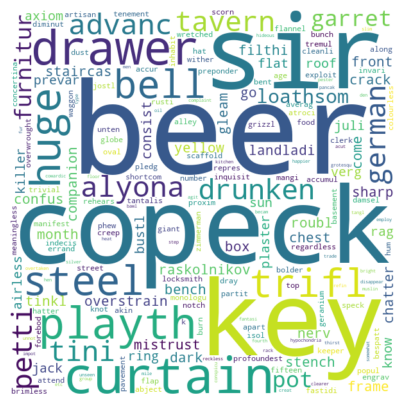

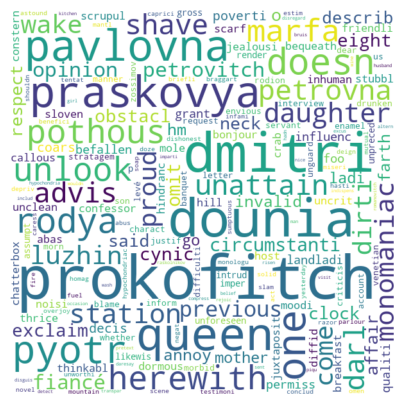

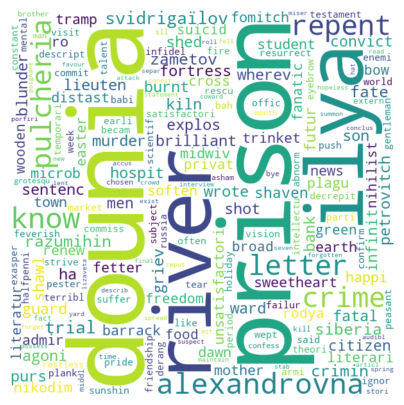

In [18]:
# Exercise 6
chapters = content.split("chapter")
chapters = chapters[1:] # first element is not a chapter
chapter_words = [prepare_word_list(ch.split()[1:]) for ch in chapters]
D = len(chapters)

word_document_occurances = Counter()
for chw in chapter_words:
    for w, _ in chw:
        word_document_occurances[w] = word_document_occurances.get(w, 0) + 1

chapter_words_weights = [{word :                                                     \
                            counter * log2(D / (1 + word_document_occurances[word])) \
                            for word, counter in chw} for chw in chapter_words]

# normalize weights to 0-100 range
for chw in chapter_words_weights:
    min_weight = min(chw.values())
    max_weight = max(chw.values())
    for word in chw:
        chw[word] = int(100 * (chw[word] - min_weight) / (max_weight - min_weight))

ids_of_chapters_to_print = [0, 15, 39]
for i in ids_of_chapters_to_print:
    wordcloud = WordCloud(width=600, height=600, background_color='white').generate_from_frequencies(chapter_words_weights[i])
    plt.figure(figsize=(5, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.show()

In [19]:
# Exercise 7
def fit_the_chapter(word: str, chapter_words_weights: list[dict]) -> list:
    fits = {i+1 : chapter_words_weights[i].get(word, float('-inf')) for i in range(len(chapter_words_weights))}
    fits = sorted(fits.items(), key=lambda x: x[1], reverse=True)
    return fits

In [20]:
# Exercise 7
print(fit_the_chapter("heaven", chapter_words_weights))

[(26, 25), (15, 13), (25, 13), (2, 12), (22, 12), (16, 10), (18, 10), (24, 10), (14, 8), (6, 7), (7, 7), (17, 7), (12, 6), (33, 6), (9, 5), (21, 5), (23, 4), (10, 3), (30, 3), (28, 2), (1, -inf), (3, -inf), (4, -inf), (5, -inf), (8, -inf), (11, -inf), (13, -inf), (19, -inf), (20, -inf), (27, -inf), (29, -inf), (31, -inf), (32, -inf), (34, -inf), (35, -inf), (36, -inf), (37, -inf), (38, -inf), (39, -inf), (40, -inf)]


In [35]:
# Exercise 8
words = content.split()
with open("stop-words.txt", "r") as file:
    stop_words = file.read().split()
words = [word for word in words if word not in stop_words]

freq_post_words = {word : {} for word in words}
for i in range(len(words) - 1):
    w1 = words[i]
    w2 = words[i+1]
    if w2 in freq_post_words[w1]:
        freq_post_words[w1][w2] += 1
    else:
        freq_post_words[w1][w2] = 1

for word in freq_post_words:
    freq_post_words[word] = sorted(freq_post_words[word].items(), key=lambda x: x[1], reverse=True)[:5]

word = words[0]
for i in range(100):
    print(word, end=' ')
    next_word_index = random.randint(0, min(4, len(freq_post_words[word]) - 1))
    word = freq_post_words[word][next_word_index][0]

crime punishment part town kind flew frenzy little room said nothing else one day yesterday thought would go see whether man run buy lock outside heard something quite young woman went room said razumihin answered raskolnikov answered dounia eyes raskolnikov said suddenly struck six weeks shall go away somewhere far much better think would never thought minute later begun look upon made haste said raskolnikov asked suddenly felt positively offended nowadays repeated though still gazed fence saw saw little face looked round eyes fixed windows chairs money pocket saw sonia stood middle room stood still went back room even could 